In [2]:
# GamePulse - Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import get_validated_dataset

# Load validated dataset
df = get_validated_dataset()

print("EDA ENVIRONMENT READY")
print("Dataset shape:", df.shape)

Dataset loaded successfully: cookie_cats.csv
Dataset shape: (90189, 5)
Schema validation passed.
Data quality validation passed.

All dataset validations passed!
Total players: 90,189
EDA ENVIRONMENT READY
Dataset shape: (90189, 5)


In [3]:
# Dataset overview

print("DATASET INFORMATION")
print("-" * 40)

df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe())

print("\nEXPERIMENT GROUPS")
display(df["version"].value_counts())

DATASET INFORMATION
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB

STATISTICAL SUMMARY


,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000



EXPERIMENT GROUPS


version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [4]:
# Player distribution analysis

player_counts = df["version"].value_counts()

player_percentages = (
    df["version"].value_counts(normalize=True) * 100
)

distribution = pd.DataFrame({
    "Player Count": player_counts,
    "Percentage": player_percentages
})

display(distribution.round(2))

,Player Count,Percentage
version,,
gate_40,45489,50.44
gate_30,44700,49.56


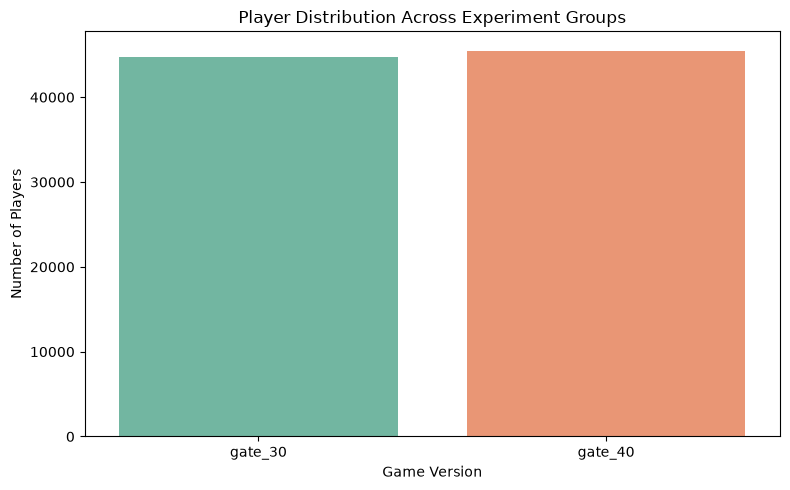

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="version",
    hue="version",
    palette="Set2",
    legend=False
)

plt.title("Player Distribution Across Experiment Groups")
plt.xlabel("Game Version")
plt.ylabel("Number of Players")

plt.tight_layout()
plt.show()

In [6]:
control_players = (df["version"] == "gate_30").sum()
test_players = (df["version"] == "gate_40").sum()

difference = abs(control_players - test_players)

print("CONTROL GROUP:", control_players)
print("TEST GROUP:", test_players)
print("PLAYER COUNT DIFFERENCE:", difference)
print(
    "GROUP SIZE DIFFERENCE (%):",
    round(difference / len(df) * 100, 2)
)

CONTROL GROUP: 44700
TEST GROUP: 45489
PLAYER COUNT DIFFERENCE: 789
GROUP SIZE DIFFERENCE (%): 0.87


In [7]:
git add notebooks/01_exploratory_data_analysis.ipynb


SyntaxError: invalid decimal literal (4185133813.py, line 1)

In [11]:
# Game rounds statistical analysis

game_round_stats = df.groupby("version")["sum_gamerounds"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(game_round_stats.round(2))


,count,mean,median,std,min,max
version,,,,,,
gate_30,44700,52.46,17.0,256.72,0,49854
gate_40,45489,51.30,16.0,103.29,0,2640


In [12]:
# Game rounds quartile analysis

quartiles = df.groupby("version")["sum_gamerounds"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).unstack()

quartiles.columns = [
    "25%", "50%", "75%", "90%", "95%", "99%"
]

display(quartiles.round(2))

,25%,50%,75%,90%,95%,99%
version,,,,,,
gate_30,5.0,17.0,50.0,135.0,222.0,493.00
gate_40,5.0,16.0,52.0,134.0,220.0,492.12


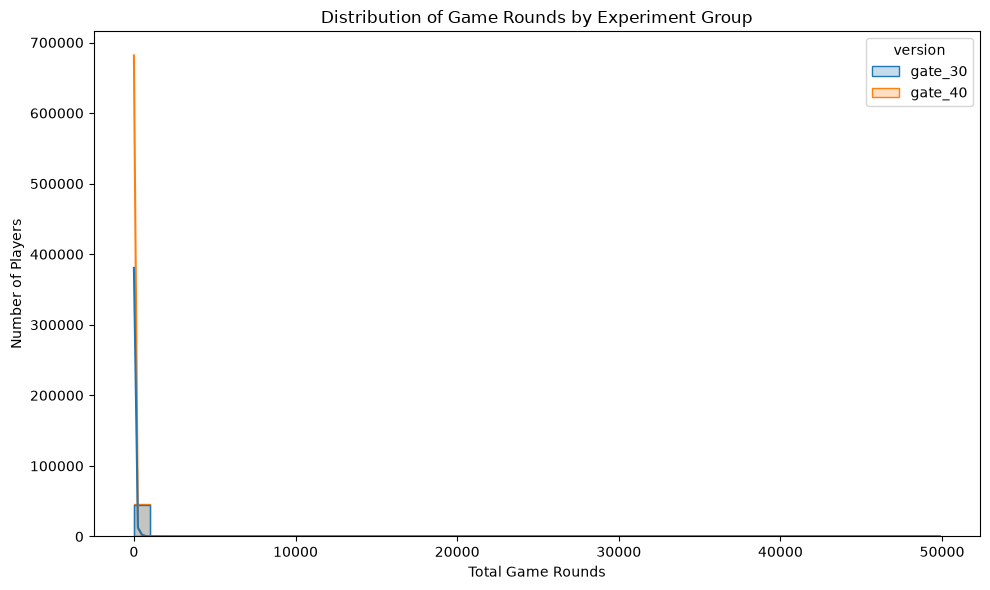

In [13]:
# Game rounds distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sum_gamerounds",
    hue="version",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Distribution of Game Rounds by Experiment Group")
plt.xlabel("Total Game Rounds")
plt.ylabel("Number of Players")

plt.tight_layout()
plt.show()

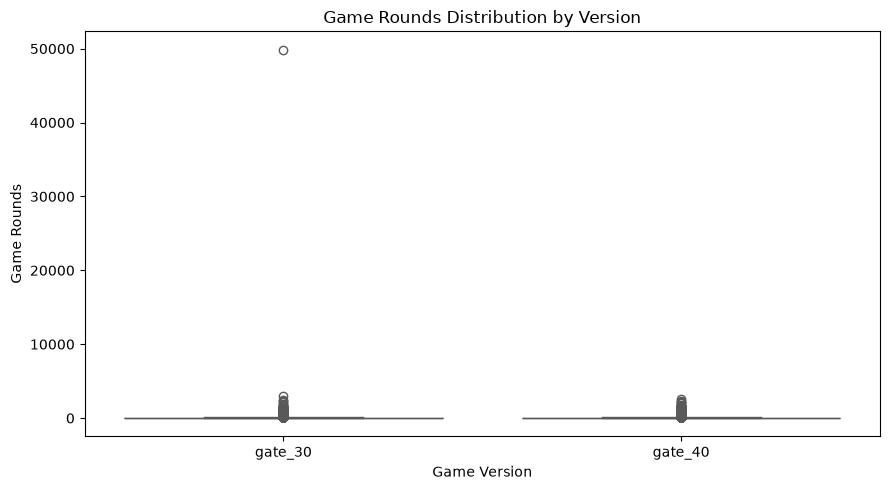

In [14]:
# Box plot of game rounds

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="version",
    y="sum_gamerounds",
    hue="version",
    palette="Set2",
    legend=False
)

plt.title("Game Rounds Distribution by Version")
plt.xlabel("Game Version")
plt.ylabel("Game Rounds")

plt.tight_layout()
plt.show()

In [15]:
# Distribution skewness

skewness = df.groupby("version")["sum_gamerounds"].skew()

print("GAME ROUNDS SKEWNESS")
display(skewness)

GAME ROUNDS SKEWNESS


version
gate_30    163.709871
gate_40      5.967288
Name: sum_gamerounds, dtype: float64

In [16]:
# Outlier detection using the IQR method

outlier_summary = []

for version, group in df.groupby("version"):

    Q1 = group["sum_gamerounds"].quantile(0.25)
    Q3 = group["sum_gamerounds"].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = group[
        (group["sum_gamerounds"] < lower_bound) |
        (group["sum_gamerounds"] > upper_bound)
    ]

    outlier_summary.append({
        "Version": version,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(group) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.round(2))

,Version,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,gate_30,5.0,50.0,45.0,-62.5,117.5,5207,11.65
1,gate_40,5.0,52.0,47.0,-65.5,122.5,5018,11.03


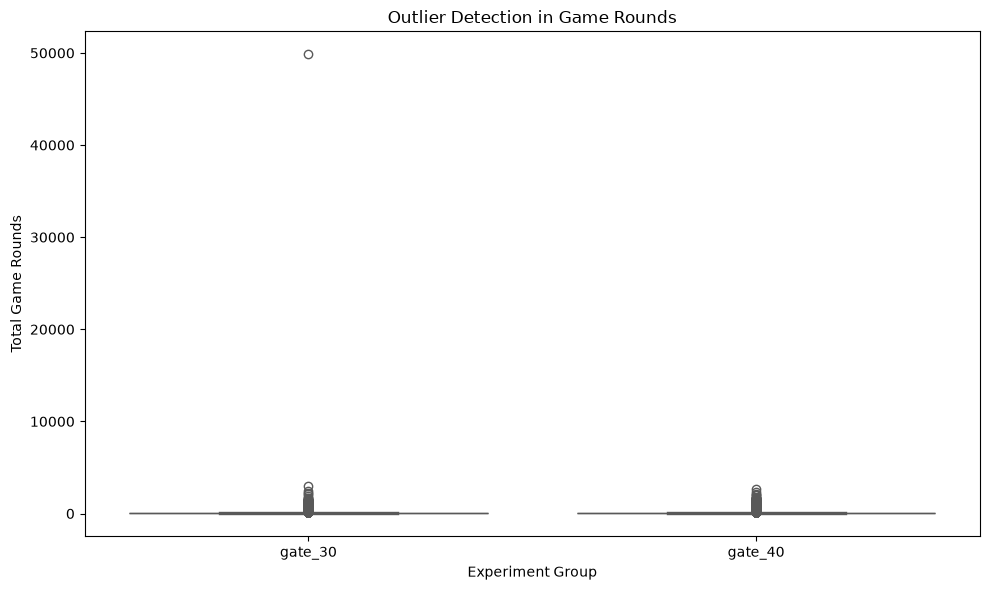

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="version",
    y="sum_gamerounds",
    hue="version",
    palette="Set2",
    legend=False
)

plt.title("Outlier Detection in Game Rounds")
plt.xlabel("Experiment Group")
plt.ylabel("Total Game Rounds")
plt.tight_layout()
plt.show()

In [18]:
print("TOP 10 PLAYERS BY GAME ROUNDS")

display(
    df.nlargest(10, "sum_gamerounds")[
        ["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]
    ]
)

TOP 10 PLAYERS BY GAME ROUNDS


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True
46344,5133952,gate_30,2251,True,True
87007,9640085,gate_30,2156,True,True
36933,4090246,gate_40,2124,True,True
88328,9791599,gate_40,2063,True,True
6536,725080,gate_40,2015,True,True


In [19]:
# Retention analysis by experiment group

retention_summary = df.groupby("version").agg(
    total_players=("userid", "count"),
    day_1_retained=("retention_1", "sum"),
    day_7_retained=("retention_7", "sum")
)

retention_summary["day_1_retention"] = (
    retention_summary["day_1_retained"]
    / retention_summary["total_players"] * 100
)

retention_summary["day_7_retention"] = (
    retention_summary["day_7_retained"]
    / retention_summary["total_players"] * 100
)

display(retention_summary.round(2))

,total_players,day_1_retained,day_7_retained,day_1_retention,day_7_retention
version,,,,,
gate_30,44700,20034,8502,44.82,19.02
gate_40,45489,20119,8279,44.23,18.20


In [20]:
# Compare retention rates between gate_30 and gate_40

retention_comparison = pd.DataFrame({
    "Metric": ["Day-1 Retention", "Day-7 Retention"],
    "gate_30 (%)": [
        retention_summary.loc["gate_30", "day_1_retention"],
        retention_summary.loc["gate_30", "day_7_retention"]
    ],
    "gate_40 (%)": [
        retention_summary.loc["gate_40", "day_1_retention"],
        retention_summary.loc["gate_40", "day_7_retention"]
    ]
})

retention_comparison["Difference (percentage points)"] = (
    retention_comparison["gate_40 (%)"]
    - retention_comparison["gate_30 (%)"]
)

display(retention_comparison.round(2))

,Metric,gate_30 (%),gate_40 (%),Difference (percentage points)
0,Day-1 Retention,44.82,44.23,-0.59
1,Day-7 Retention,19.02,18.20,-0.82


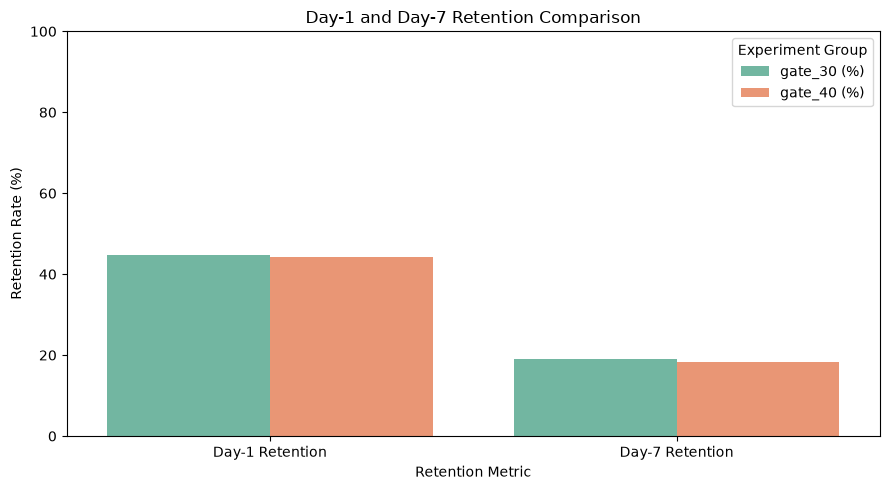

In [21]:
# Retention rate comparison chart

retention_plot = retention_comparison.melt(
    id_vars="Metric",
    value_vars=["gate_30 (%)", "gate_40 (%)"],
    var_name="Experiment Group",
    value_name="Retention Rate"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=retention_plot,
    x="Metric",
    y="Retention Rate",
    hue="Experiment Group",
    palette="Set2"
)

plt.title("Day-1 and Day-7 Retention Comparison")
plt.xlabel("Retention Metric")
plt.ylabel("Retention Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()

In [22]:
from scipy.stats import norm

# Statistical significance testing

alpha = 0.05

metrics = {
    "Day-1 Retention": "day_1_retained",
    "Day-7 Retention": "day_7_retained"
}

test_results = []

for metric_name, column in metrics.items():

    # Success counts
    success_30 = retention_summary.loc["gate_30", column]
    success_40 = retention_summary.loc["gate_40", column]

    # Total players
    n_30 = retention_summary.loc["gate_30", "total_players"]
    n_40 = retention_summary.loc["gate_40", "total_players"]

    # Retention proportions
    p_30 = success_30 / n_30
    p_40 = success_40 / n_40

    # Pooled proportion
    pooled_p = (success_30 + success_40) / (n_30 + n_40)

    # Standard error under the null hypothesis
    standard_error = (
        pooled_p * (1 - pooled_p) * (1/n_30 + 1/n_40)
    ) ** 0.5

    # Z statistic
    z_statistic = (p_40 - p_30) / standard_error

    # Two-sided p-value
    p_value = 2 * norm.sf(abs(z_statistic))

    # Unpooled standard error for the confidence interval
    ci_standard_error = (
        p_30 * (1 - p_30) / n_30
        + p_40 * (1 - p_40) / n_40
    ) ** 0.5

    difference = p_40 - p_30

    margin_of_error = norm.ppf(0.975) * ci_standard_error

    lower_ci = difference - margin_of_error
    upper_ci = difference + margin_of_error

    # Decision
    decision = (
        "Statistically Significant"
        if p_value < alpha
        else "Not Statistically Significant"
    )

    test_results.append({
        "Metric": metric_name,
        "Gate 30 Retention (%)": p_30 * 100,
        "Gate 40 Retention (%)": p_40 * 100,
        "Difference (pp)": difference * 100,
        "Z Statistic": z_statistic,
        "P-value": p_value,
        "95% CI Lower (pp)": lower_ci * 100,
        "95% CI Upper (pp)": upper_ci * 100,
        "Decision": decision
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Metric,Gate 30 Retention (%),Gate 40 Retention (%),Difference (pp),Z Statistic,P-value,95% CI Lower (pp),95% CI Upper (pp),Decision
0,Day-1 Retention,44.8188,44.2283,-0.5905,-1.7841,0.0744,-1.2392,0.0582,Not Statistically Significant
1,Day-7 Retention,19.0201,18.2000,-0.8201,-3.1644,0.0016,-1.3282,-0.3121,Statistically Significant


In [23]:
# Relative retention impact

day_1_gate_30 = retention_summary.loc["gate_30", "day_1_retention"]
day_1_gate_40 = retention_summary.loc["gate_40", "day_1_retention"]

day_7_gate_30 = retention_summary.loc["gate_30", "day_7_retention"]
day_7_gate_40 = retention_summary.loc["gate_40", "day_7_retention"]

day_1_relative_change = (
    (day_1_gate_40 - day_1_gate_30)
    / day_1_gate_30
) * 100

day_7_relative_change = (
    (day_7_gate_40 - day_7_gate_30)
    / day_7_gate_30
) * 100

print("RELATIVE RETENTION IMPACT")
print("-" * 40)

print(f"Day-1 Relative Change: {day_1_relative_change:.2f}%")
print(f"Day-7 Relative Change: {day_7_relative_change:.2f}%")

RELATIVE RETENTION IMPACT
----------------------------------------
Day-1 Relative Change: -1.32%
Day-7 Relative Change: -4.31%


In [24]:
# Bootstrap confidence intervals for retention differences

import numpy as np

rng = np.random.default_rng(42)

n_bootstrap = 10000

bootstrap_results = []

metrics = {
    "Day-1 Retention": "retention_1",
    "Day-7 Retention": "retention_7"
}

for metric_name, column in metrics.items():

    # Retention values for each experiment group
    gate_30 = df.loc[
        df["version"] == "gate_30", column
    ].astype(int).to_numpy()

    gate_40 = df.loc[
        df["version"] == "gate_40", column
    ].astype(int).to_numpy()

    # Original retention rates
    p_30 = gate_30.mean()
    p_40 = gate_40.mean()

    observed_difference = p_40 - p_30

    # Bootstrap resampling of binary retention outcomes
    boot_30 = rng.binomial(
        n=len(gate_30),
        p=p_30,
        size=n_bootstrap
    ) / len(gate_30)

    boot_40 = rng.binomial(
        n=len(gate_40),
        p=p_40,
        size=n_bootstrap
    ) / len(gate_40)

    # Difference in each bootstrap resample
    bootstrap_differences = boot_40 - boot_30

    # 95% percentile confidence interval
    lower_ci = np.percentile(bootstrap_differences, 2.5)
    upper_ci = np.percentile(bootstrap_differences, 97.5)

    bootstrap_results.append({
        "Metric": metric_name,
        "Observed Difference (pp)": observed_difference * 100,
        "Bootstrap CI Lower (pp)": lower_ci * 100,
        "Bootstrap CI Upper (pp)": upper_ci * 100
    })

bootstrap_results_df = pd.DataFrame(bootstrap_results)

display(bootstrap_results_df.round(4))

,Metric,Observed Difference (pp),Bootstrap CI Lower (pp),Bootstrap CI Upper (pp)
0,Day-1 Retention,-0.5905,-1.2522,0.0606
1,Day-7 Retention,-0.8201,-1.3244,-0.3074


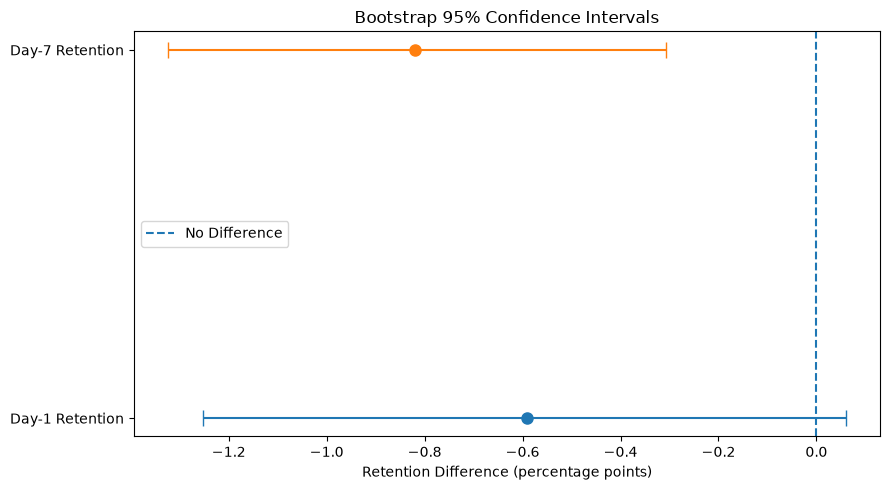

In [25]:
# Visualize bootstrap confidence intervals

plt.figure(figsize=(9, 5))

for i, row in bootstrap_results_df.iterrows():

    difference = row["Observed Difference (pp)"]

    lower_error = difference - row["Bootstrap CI Lower (pp)"]
    upper_error = row["Bootstrap CI Upper (pp)"] - difference

    plt.errorbar(
        difference,
        i,
        xerr=[[lower_error], [upper_error]],
        fmt="o",
        capsize=6,
        markersize=8
    )

plt.axvline(0, linestyle="--", label="No Difference")

plt.yticks(
    range(len(bootstrap_results_df)),
    bootstrap_results_df["Metric"]
)

plt.xlabel("Retention Difference (percentage points)")
plt.title("Bootstrap 95% Confidence Intervals")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# Robustness analysis: impact of extreme game-round values

robustness_results = []

for version, group in df.groupby("version"):

    # Calculate IQR boundaries
    Q1 = group["sum_gamerounds"].quantile(0.25)
    Q3 = group["sum_gamerounds"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep all players
    original_mean = group["sum_gamerounds"].mean()
    original_median = group["sum_gamerounds"].median()

    # Exclude IQR outliers for sensitivity analysis only
    filtered_group = group[
        group["sum_gamerounds"].between(
            lower_bound, upper_bound
        )
    ]

    filtered_mean = filtered_group["sum_gamerounds"].mean()
    filtered_median = filtered_group["sum_gamerounds"].median()

    robustness_results.append({
        "Version": version,
        "Original Mean": original_mean,
        "Filtered Mean": filtered_mean,
        "Original Median": original_median,
        "Filtered Median": filtered_median,
        "Original Players": len(group),
        "Filtered Players": len(filtered_group)
    })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df.round(2))

,Version,Original Mean,Filtered Mean,Original Median,Filtered Median,Original Players,Filtered Players
0,gate_30,52.46,23.60,17.0,13.0,44700,39493
1,gate_40,51.30,24.25,16.0,13.0,45489,40471


In [27]:
# Calculate percentage change in mean game rounds

robustness_df["Mean Reduction (%)"] = (
    (
        robustness_df["Original Mean"]
        - robustness_df["Filtered Mean"]
    )
    / robustness_df["Original Mean"]
) * 100

display(robustness_df.round(2))

,Version,Original Mean,Filtered Mean,Original Median,Filtered Median,Original Players,Filtered Players,Mean Reduction (%)
0,gate_30,52.46,23.60,17.0,13.0,44700,39493,55.02
1,gate_40,51.30,24.25,16.0,13.0,45489,40471,52.74


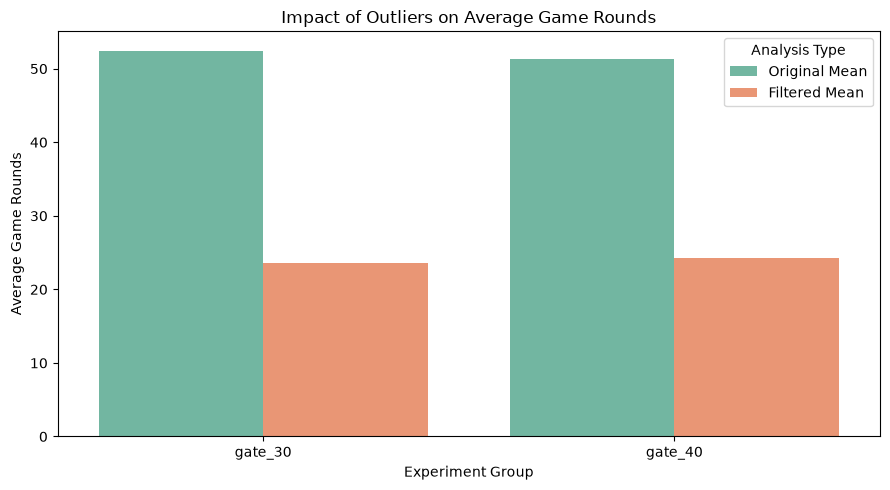

In [28]:
# Compare original and filtered mean game rounds

mean_comparison = robustness_df.melt(
    id_vars="Version",
    value_vars=["Original Mean", "Filtered Mean"],
    var_name="Analysis Type",
    value_name="Average Game Rounds"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=mean_comparison,
    x="Version",
    y="Average Game Rounds",
    hue="Analysis Type",
    palette="Set2"
)

plt.title("Impact of Outliers on Average Game Rounds")
plt.xlabel("Experiment Group")
plt.ylabel("Average Game Rounds")
plt.tight_layout()
plt.show()

In [29]:
# GamePulse - Final EDA Summary

print("=" * 60)
print("GAMEPULSE: FINAL EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print("\n1. DATASET OVERVIEW")
print("-" * 40)
print(f"Total players: {len(df):,}")
print(f"Experiment groups: {df['version'].nunique()}")
print(f"Total columns: {df.shape[1]}")

print("\n2. EXPERIMENT GROUP DISTRIBUTION")
print("-" * 40)
print(df["version"].value_counts())

print("\n3. RETENTION COMPARISON")
print("-" * 40)
display(retention_comparison.round(4))

print("\n4. STATISTICAL TEST RESULTS")
print("-" * 40)
display(test_results_df.round(4))

print("\n5. BOOTSTRAP CONFIDENCE INTERVALS")
print("-" * 40)
display(bootstrap_results_df.round(4))

print("\n6. OUTLIER ANALYSIS")
print("-" * 40)
display(outlier_df.round(2))

print("\n7. ROBUSTNESS ANALYSIS")
print("-" * 40)
display(robustness_df.round(2))

print("\n" + "=" * 60)
print("EDA SUMMARY GENERATED SUCCESSFULLY")
print("=" * 60)

GAMEPULSE: FINAL EXPLORATORY DATA ANALYSIS

1. DATASET OVERVIEW
----------------------------------------
Total players: 90,189
Experiment groups: 2
Total columns: 5

2. EXPERIMENT GROUP DISTRIBUTION
----------------------------------------
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

3. RETENTION COMPARISON
----------------------------------------


,Metric,gate_30 (%),gate_40 (%),Difference (percentage points)
0,Day-1 Retention,44.8188,44.2283,-0.5905
1,Day-7 Retention,19.0201,18.2000,-0.8201



4. STATISTICAL TEST RESULTS
----------------------------------------


,Metric,Gate 30 Retention (%),Gate 40 Retention (%),Difference (pp),Z Statistic,P-value,95% CI Lower (pp),95% CI Upper (pp),Decision
0,Day-1 Retention,44.8188,44.2283,-0.5905,-1.7841,0.0744,-1.2392,0.0582,Not Statistically Significant
1,Day-7 Retention,19.0201,18.2000,-0.8201,-3.1644,0.0016,-1.3282,-0.3121,Statistically Significant



5. BOOTSTRAP CONFIDENCE INTERVALS
----------------------------------------


,Metric,Observed Difference (pp),Bootstrap CI Lower (pp),Bootstrap CI Upper (pp)
0,Day-1 Retention,-0.5905,-1.2522,0.0606
1,Day-7 Retention,-0.8201,-1.3244,-0.3074



6. OUTLIER ANALYSIS
----------------------------------------


,Version,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,gate_30,5.0,50.0,45.0,-62.5,117.5,5207,11.65
1,gate_40,5.0,52.0,47.0,-65.5,122.5,5018,11.03



7. ROBUSTNESS ANALYSIS
----------------------------------------


,Version,Original Mean,Filtered Mean,Original Median,Filtered Median,Original Players,Filtered Players,Mean Reduction (%)
0,gate_30,52.46,23.60,17.0,13.0,44700,39493,55.02
1,gate_40,51.30,24.25,16.0,13.0,45489,40471,52.74



EDA SUMMARY GENERATED SUCCESSFULLY
